# Practical ARIMA Forecasting Notebook

This notebook demonstrates **AutoRegressive Integrated Moving Average (ARIMA)** forecasting using a simple daily sales example.

We will:
1. Create sample sales data.
2. Plot the time series.
3. Split the data into training and testing sets.
4. Fit an `ARIMA(1,1,0)` model.
5. Forecast future sales.
6. Compare predictions with actual values.
7. Try other `(p, d, q)` combinations.


## 1. Install the required libraries

Run this once if the packages are not already installed.

In [1]:
%pip install pandas matplotlib statsmodels scikit-learn -q

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Import libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error


## 3. Create a practical sales dataset

Imagine these are daily sales from a shop. The data has a slowly increasing trend plus random variation.

In [3]:
np.random.seed(42)

dates = pd.date_range(start='2026-01-01', periods=120, freq='D')

trend = np.linspace(100, 180, 120)
noise = np.random.normal(0, 5, 120)

sales = trend + noise

df = pd.DataFrame({
    'date': dates,
    'sales': sales.round(0)
})

df.head(10)

,date,sales
0,2026-01-01,102.0
1,2026-01-02,100.0
2,2026-01-03,105.0
3,2026-01-04,110.0
4,2026-01-05,102.0
5,2026-01-06,102.0
6,2026-01-07,112.0
7,2026-01-08,109.0
8,2026-01-09,103.0
9,2026-01-10,109.0


## 4. Plot the sales series

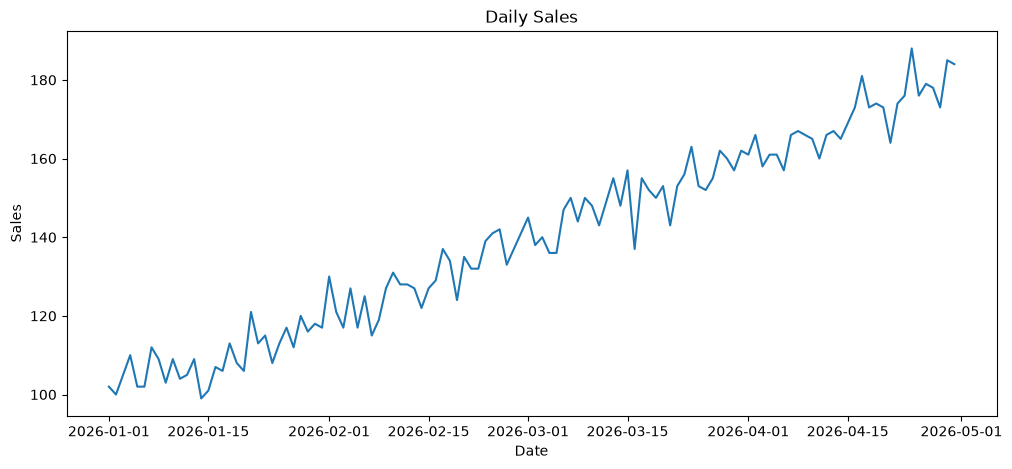

In [4]:
plt.figure(figsize=(12, 5))
plt.plot(df['date'], df['sales'])
plt.title('Daily Sales')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.show()

## 5. Understand the `d = 1` differencing step

For `ARIMA(1,1,0)`, the middle value `d=1` means the model differences the series once:

$$difference_t = sales_t - sales_{t-1}$$

Instead of directly modelling total sales, ARIMA can model how sales change from one day to the next.

In [5]:
df['sales_difference'] = df['sales'].diff()

df[['date', 'sales', 'sales_difference']].head(10)

,date,sales,sales_difference
0,2026-01-01,102.0,NaN
1,2026-01-02,100.0,-2.0
2,2026-01-03,105.0,5.0
3,2026-01-04,110.0,5.0
4,2026-01-05,102.0,-8.0
5,2026-01-06,102.0,0.0
6,2026-01-07,112.0,10.0
7,2026-01-08,109.0,-3.0
8,2026-01-09,103.0,-6.0
9,2026-01-10,109.0,6.0


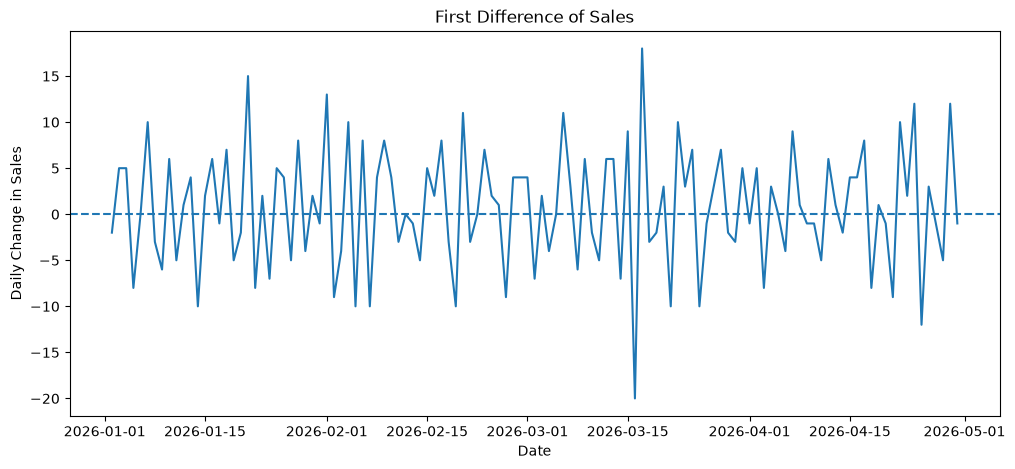

In [6]:
plt.figure(figsize=(12, 5))
plt.plot(df['date'], df['sales_difference'])
plt.axhline(0, linestyle='--')
plt.title('First Difference of Sales')
plt.xlabel('Date')
plt.ylabel('Daily Change in Sales')
plt.show()

## 6. Split the data into training and testing sets

We will train on the first 100 days and test the forecast on the final 20 days.

In [7]:
train = df.iloc[:100].copy()
test = df.iloc[100:].copy()

print('Training rows:', len(train))
print('Testing rows :', len(test))

Training rows: 100
Testing rows : 20


## 7. Fit `ARIMA(1,1,0)`

`ARIMA(p, d, q)` means:

- `p`: AutoRegressive order — how many previous values are considered.
- `d`: Integrated order — how many times differencing is applied.
- `q`: Moving Average order — how many previous forecast errors are considered.

Here we use:

```python
ARIMA(1, 1, 0)
```

So we use one previous relationship, difference once, and use no Moving Average error term.

In [8]:
model = ARIMA(train['sales'], order=(1, 1, 0))
model_fit = model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  sales   No. Observations:                  100
Model:                 ARIMA(1, 1, 0)   Log Likelihood                -313.828
Date:                Fri, 07 Aug 2026   AIC                            631.656
Time:                        13:10:41   BIC                            636.846
Sample:                             0   HQIC                           633.756
                                - 100                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4704      0.092     -5.134      0.000      -0.650      -0.291
sigma2        33.1009      5.344      6.194      0.000      22.626      43.576
Ljung-Box (L1) (Q):                   3.23   Jarque-

### Look at the learned AutoRegressive coefficient

The coefficient is estimated from the historical data. We do **not** manually choose a value such as `0.8`.

In [9]:
print(model_fit.params)

ar.L1     -0.470421
sigma2    33.100868
dtype: float64


## 8. Forecast the next 20 days

In [10]:
forecast = model_fit.forecast(steps=len(test))

test['forecast'] = np.array(forecast)

test[['date', 'sales', 'forecast']].head(10)

,date,sales,forecast
100,2026-04-11,160.0,165.470421
101,2026-04-12,166.0,165.249125
102,2026-04-13,167.0,165.353227
103,2026-04-14,165.0,165.304255
104,2026-04-15,169.0,165.327293
105,2026-04-16,173.0,165.316456
106,2026-04-17,181.0,165.321554
107,2026-04-18,173.0,165.319155
108,2026-04-19,174.0,165.320284
109,2026-04-20,173.0,165.319753


## 9. Plot actual values vs ARIMA predictions

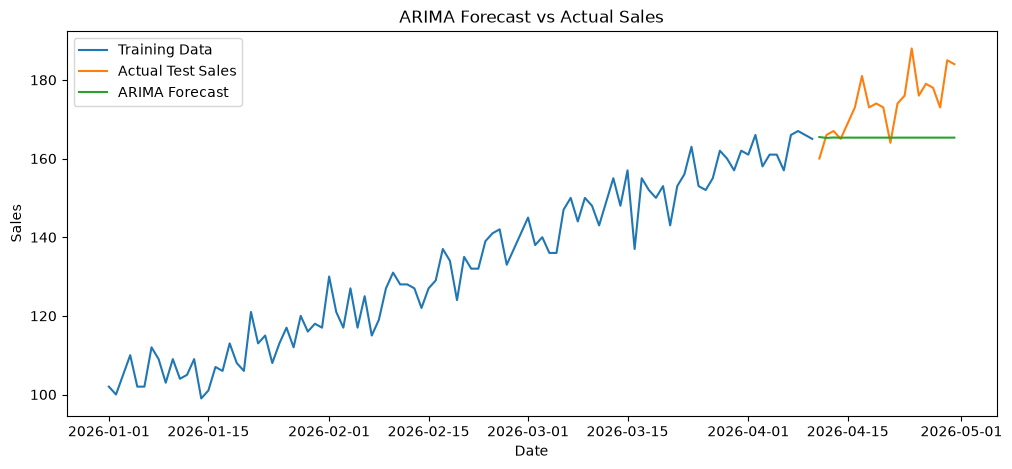

In [11]:
plt.figure(figsize=(12, 5))
plt.plot(train['date'], train['sales'], label='Training Data')
plt.plot(test['date'], test['sales'], label='Actual Test Sales')
plt.plot(test['date'], test['forecast'], label='ARIMA Forecast')
plt.title('ARIMA Forecast vs Actual Sales')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.show()

## 10. Calculate forecast error

In [12]:
mae = mean_absolute_error(test['sales'], test['forecast'])
rmse = np.sqrt(mean_squared_error(test['sales'], test['forecast']))

print(f'Mean Absolute Error: {mae:.2f}')
print(f'Root Mean Squared Error: {rmse:.2f}')

Mean Absolute Error: 9.28
Root Mean Squared Error: 11.20


## 11. Forecast completely unseen future dates

Now train ARIMA on all 120 days and forecast the next 10 days.

In [14]:
final_model = ARIMA(df['sales'], order=(1, 1, 0))
final_fit = final_model.fit()

future_steps = 10
future_forecast = final_fit.forecast(steps=future_steps)

future_dates = pd.date_range(
    start=df['date'].iloc[-1] + pd.Timedelta(days=1),
    periods=future_steps,
    freq='D'
)

future_df = pd.DataFrame({
    'date': future_dates,
    'predicted_sales': np.array(future_forecast)
})

future_df

,date,predicted_sales
0,2026-05-01,184.456135
1,2026-05-02,184.248076
2,2026-05-03,184.342979
3,2026-05-04,184.299690
4,2026-05-05,184.319436
5,2026-05-06,184.310429
6,2026-05-07,184.314537
7,2026-05-08,184.312664
8,2026-05-09,184.313518
9,2026-05-10,184.313128


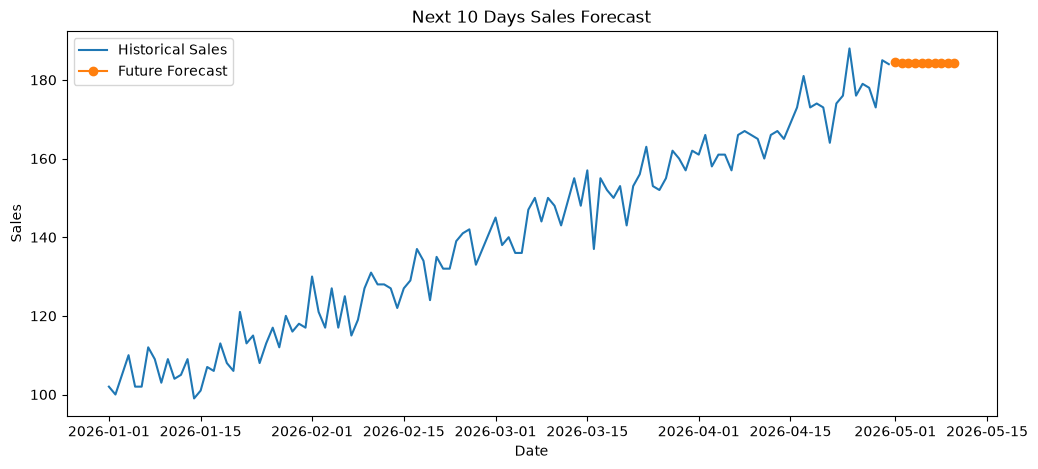

In [15]:
plt.figure(figsize=(12, 5))
plt.plot(df['date'], df['sales'], label='Historical Sales')
plt.plot(future_df['date'], future_df['predicted_sales'], marker='o', label='Future Forecast')
plt.title('Next 10 Days Sales Forecast')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.show()

## 12. Experiment with different `(p, d, q)` values

Try changing the values below and compare the Mean Absolute Error.

For example:

- `ARIMA(1,1,0)`
- `ARIMA(2,1,0)`
- `ARIMA(1,1,1)`
- `ARIMA(2,1,1)`
- `ARIMA(3,1,2)`

In [16]:
orders_to_try = [
    (1, 1, 0),
    (2, 1, 0),
    (1, 1, 1),
    (2, 1, 1),
    (3, 1, 2),
]

results = []

for order in orders_to_try:
    try:
        model = ARIMA(train['sales'], order=order)
        fitted = model.fit()
        preds = fitted.forecast(steps=len(test))

        mae = mean_absolute_error(test['sales'], preds)

        results.append({
            'order': str(order),
            'MAE': mae,
            'AIC': fitted.aic
        })
    except Exception as e:
        print(f'Could not fit {order}: {e}')

results_df = pd.DataFrame(results).sort_values('MAE')
results_df

,order,MAE,AIC
1,"(2, 1, 0)",9.079400,624.503617
0,"(1, 1, 0)",9.284428,631.656141
3,"(2, 1, 1)",9.449915,621.064905
4,"(3, 1, 2)",9.501901,622.364497
2,"(1, 1, 1)",9.598719,619.711974


## 13. Use your own CSV file

If your real dataset contains something like:

| date | sales |
|---|---:|
| 2026-01-01 | 120 |
| 2026-01-02 | 131 |

replace the generated data with:

In [ ]:
# Example for your own file:
# df = pd.read_csv('sales.csv')
# df['date'] = pd.to_datetime(df['date'])
# df = df.sort_values('date')
# df.head()

## Key idea

For an `ARIMA(1,1,0)` model, you can mentally think of the process as:

```text
Historical sales
      ↓
Difference the values because d = 1
      ↓
Learn the relationship with previous differences because p = 1
      ↓
Predict the next change
      ↓
Add that change back to the previous sales value
      ↓
Future sales forecast
```

The important part is that the model estimates its coefficients from the training data automatically.